# CI failure prediction on GitHub Actions - CART decision tree

Trains and evaluates the from-scratch CART tree (`tree/cart.py`, Breiman et al., 1984) on the n8n master runs, with the frozen feature lists from `feature_selection.ipynb`.

**Protocol.** The dev segment (first 20% of runs) is followed by 5 expanding-window folds. Each train set is dev + the window so far; its last 20% is the **validation** tail. The hyperparameters, the pruning alpha and the decision threshold are chosen on validation only (`tree/tune.py`); each test fold is read once, after the tree is final.

**Targets.** T2 (runs whose previous run passed) is the main target; T1 (all runs) is secondary, for the comparison with Parrot.

**Baselines.** Parrot (previous outcome; on T2 always "pass"), majority class, and sklearn's `DecisionTreeClassifier` with the same choices per fold (a reference for the implementation, not a competitor).

**Random forest.** Section 9 repeats the CV with a forest of 100 bagged CART trees (`tree/forest.py`, Breiman, 2001): a stronger but not explainable comparison point.

In [1]:
from dataclasses import replace
import numpy as np
import pandas as pd
import plotly.express as px
from sklearn.metrics import matthews_corrcoef
from sklearn.tree import DecisionTreeClassifier
from acise_p2_cidt.analysis.features import load_features
from acise_p2_cidt.collect.gh_runs import N8N_MASTER
from acise_p2_cidt.data.load import Dataset, load
from acise_p2_cidt.metrics.metrics import majority, parrot
from acise_p2_cidt.stats import tests as st
from acise_p2_cidt.training.cv import dev_split, folds, prepare, run_cv
from acise_p2_cidt.tree import forest, tune
from acise_p2_cidt.tree.cart import CART
from acise_p2_cidt.viz import plots

REPO = N8N_MASTER.repo
REGIME = ("2026-02-10", "2026-06-10")  # Node 25.x failure regime
TARGETS = ("T2", "T1")
METRICS = ["mcc", "f1", "precision", "recall", "accuracy", "pct_builds_saved", "pct_failures_caught"]
data = {t: load(REPO, t) for t in TARGETS}
feats = {t: load_features(t, REPO) for t in TARGETS}
fold_lists = {t: folds(data[t]) for t in TARGETS}
splits = {t: [prepare(data[t], feats[t], f) for f in fold_lists[t]] for t in TARGETS}
pd.DataFrame(
    {
        t: {
            "rows": ds.meta["n_rows"],
            "failed": ds.meta["n_failed"],
            "fail_%": round(100 * ds.y.mean(), 2),
            "dev_rows": ds.meta["n_dev"],
            "features": len(feats[t]),
        }
        for t, ds in data.items()
    }
)

,T2,T1
rows,7626.00,10265.0
failed,1241.00,2700.0
fail_%,16.27,26.3
dev_rows,1525.00,2053.0
features,11.00,18.0


## 1. CART walkthrough (T2, dev split)

One tree on the dev split (head of dev = fit rows, tail = validation), depth 3, `class_weight="balanced"`. Each internal node is a test `x <= t` in raw units (no scaling, see the plan); each leaf gives P(fail) as the weighted share of failed runs that reach it.

In [2]:
dev = dev_split(data["T2"], feats["T2"])
demo = CART(max_depth=3, min_samples_leaf=10, class_weight="balanced").fit(dev.X_fit, dev.y_fit)
print(f"depth {demo.depth_}, leaves {demo.n_leaves_}\n")
print(demo.export_text())

depth 3, leaves 8

|--- runs_since_last_fail <= 28.5
|   |--- files_since_green <= 2.5
|   |   |--- secs_since_last_fail <= 6810.5
|   |   |   |--- leaf: P(fail) = 0.00 from 48 runs
|   |   |--- secs_since_last_fail > 6810.5
|   |   |   |--- leaf: P(fail) = 0.46 from 221 runs
|   |--- files_since_green > 2.5
|   |   |--- file_prior_changes <= 0.45
|   |   |   |--- leaf: P(fail) = 0.00 from 22 runs
|   |   |--- file_prior_changes > 0.45
|   |   |   |--- leaf: P(fail) = 0.57 from 747 runs
|--- runs_since_last_fail > 28.5
|   |--- runs_since_last_fail <= 62.5
|   |   |--- fail_rate_7d <= 0.0414945
|   |   |   |--- leaf: P(fail) = 0.49 from 11 runs
|   |   |--- fail_rate_7d > 0.0414945
|   |   |   |--- leaf: P(fail) = 0.00 from 148 runs
|   |--- runs_since_last_fail > 62.5
|   |   |--- file_prior_changes <= 23.75
|   |   |   |--- leaf: P(fail) = 0.44 from 13 runs
|   |   |--- file_prior_changes > 23.75
|   |   |   |--- leaf: P(fail) = 0.86 from 10 runs


`explain` gives the path of one run: the tests it passed, then the leaf. Shown for the first failed run of the validation tail.

runs_since_last_fail = 12 <= 28.5
files_since_green = 5 > 2.5
file_prior_changes = 534.5 > 0.45
leaf: P(fail) = 0.57 from 747 runs
actual: fail


[11/03/26 14:38:12] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_demo_T2.*

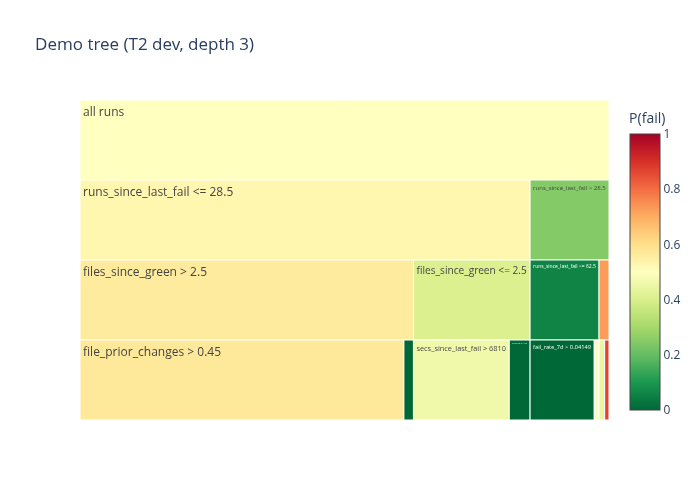

In [3]:
i = int(np.flatnonzero(dev.y_val.to_numpy())[0])
print("\n".join(demo.explain(dev.X_val.iloc[i])))
print("actual: fail")
plots.save(
    plots.tree_icicle(demo.tree_, demo.feature_names_, max_depth=3).update_layout(title="Demo tree (T2 dev, depth 3)"),
    "tree_demo_T2",
)

**Reference check.** sklearn's tree with the same parameters. When two splits have exactly the same gain, sklearn takes one at random (it shuffles the features), CART takes the first column, so the two trees can differ on ties only. `tests/test_cart.py` checks that every difference is such a tie. sklearn fits on float32, so its input is cast here.

In [4]:
X32 = dev.X_fit.astype("float32")
sk = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, class_weight="balanced", random_state=0).fit(X32, dev.y_fit)
agree = np.mean(demo.predict(dev.X_fit) == sk.predict(X32).astype(bool))
print(f"root impurity: CART {demo.tree_.impurity[0]:.6f}, sklearn {sk.tree_.impurity[0]:.6f}")
print(f"leaves: CART {demo.n_leaves_}, sklearn {sk.get_n_leaves()}; training predictions agree on {agree:.1%}")

root impurity: CART 0.500000, sklearn 0.500000
leaves: CART 8, sklearn 8; training predictions agree on 99.2%


## 2. Overfitting control (T2)

**Depth.** In each CV fold, an unpruned tree per depth (`min_samples_leaf=10`, Gini, balanced), scored at threshold 0.5 on the fit rows and on the validation tail. A train line that keeps rising while the validation line stays flat is overfitting.

[11/03/26 14:38:18] INFO     Saved figure:                                                                         
                             /home/aprofir/uni/ACISE/projects/2/results/figures/tree_valcurve_depth_T2.*

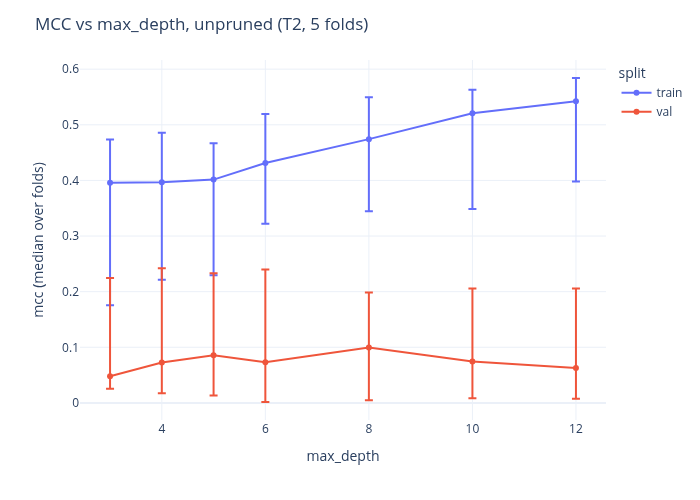

In [5]:
BASE = {"min_samples_leaf": 10, "criterion": "gini", "class_weight": "balanced"}
rows = []
for k, s in enumerate(splits["T2"]):
    for d in [*tune.GRID["max_depth"], 10, 12]:
        m = CART(max_depth=d, **BASE).fit(s.X_fit, s.y_fit)
        for name, X, y in (("train", s.X_fit, s.y_fit), ("val", s.X_val, s.y_val)):
            rows.append({"fold": k, "max_depth": d, "split": name, "mcc": matthews_corrcoef(y, m.predict(X))})
plots.save(
    plots.validation_curve(pd.DataFrame(rows), "max_depth").update_layout(title="MCC vs max_depth, unpruned (T2, 5 folds)"),
    "tree_valcurve_depth_T2",
)

**Pruning.** A depth-8 tree on the dev split, scored at every alpha of its cost-complexity path. `tune.choose_alpha` takes the alpha with the best validation MCC (ties: the larger alpha, the smaller tree).

chosen alpha: 0.002555645625851616


[11/03/26 14:38:23] INFO     Saved figure:                                                                         
                             /home/aprofir/uni/ACISE/projects/2/results/figures/tree_valcurve_alpha_T2.*

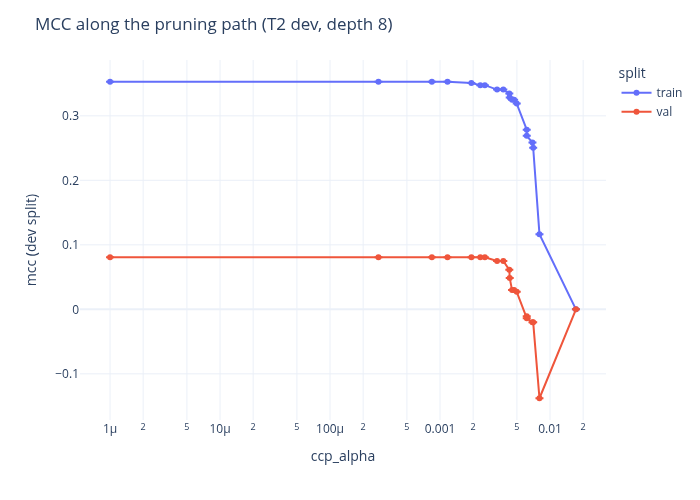

In [6]:
deep = CART(max_depth=8, **BASE).fit(dev.X_fit, dev.y_fit)
rows = []
for a in np.unique(deep.cost_complexity_path()[0]):
    p = deep.pruned(a)
    for name, X, y in (("train", dev.X_fit, dev.y_fit), ("val", dev.X_val, dev.y_val)):
        # alpha 0 (the unpruned tree) is drawn at 1e-6, so it fits on the log axis
        rows.append({"ccp_alpha": max(a, 1e-6), "split": name, "mcc": matthews_corrcoef(y, p.predict(X)), "leaves": p.n_leaves_})
alpha_df = pd.DataFrame(rows)
print("chosen alpha:", tune.choose_alpha(deep, dev))
plots.save(
    plots.validation_curve(alpha_df, "ccp_alpha", log_x=True)
    .update_layout(title="MCC along the pruning path (T2 dev, depth 8)")
    .update_yaxes(title_text="mcc (dev split)"),
    "tree_valcurve_alpha_T2",
)

## 3. Tuning on the dev split

The full grid (`max_depth` x `min_samples_leaf` x criterion x class weight = 60 points) on the dev split, as in project 1. For each point: fit, prune on validation, tune the threshold on validation. The CV below repeats this inside every fold, so this table only shows how flat the grid is.

In [7]:
best_dev, grid_dev = tune.grid_search(dev)
print(best_dev)
grid_dev.sort_values("val_mcc", ascending=False).head(10).round(4)

Choice(params={'max_depth': 6, 'min_samples_leaf': 5, 'criterion': 'gini', 'class_weight': None}, alpha=0.0010342457089595886, threshold=0.5, val_mcc=0.20112791255844226)


,max_depth,min_samples_leaf,criterion,class_weight,alpha,threshold,val_mcc,depth,n_leaves
48,8,5,gini,NaN,0.0011,0.5000,0.2011,6,11
36,6,5,gini,NaN,0.0010,0.5000,0.2011,6,11
24,5,5,gini,NaN,0.0009,0.5000,0.1832,5,10
50,8,5,entropy,NaN,0.0010,0.5000,0.1631,8,54
38,6,5,entropy,NaN,0.0010,0.5000,0.1631,6,31
59,8,20,entropy,balanced,0.0045,0.8573,0.1512,8,25
51,8,5,entropy,balanced,0.0072,0.7916,0.1512,8,31
49,8,5,gini,balanced,0.0038,0.8277,0.1512,8,31
55,8,10,entropy,balanced,0.0041,0.8277,0.1512,8,30
53,8,10,gini,balanced,0.0026,0.8277,0.1512,8,31


## 4. Cross-validation

Each fold: grid search on the validation tail, then one prediction of the test fold. `sklearn` uses CART's choice of each fold (params, alpha, threshold); it shows how much the from-scratch implementation itself changes the result.

In [8]:
def sklearn_ref(choices: list[tune.Choice]):
    """sklearn tree with CART's choice per fold; run_cv visits the folds in order."""
    it = iter(choices)

    def fit_predict(split):
        c = next(it)
        m = DecisionTreeClassifier(**c.params, ccp_alpha=c.alpha, random_state=0).fit(split.X_fit, split.y_fit)
        return m.predict_proba(split.X_test)[:, 1] > c.threshold

    return fit_predict


results, payloads = {}, {}
for t in TARGETS:
    print(f"Target: {t}")
    ds, f = data[t], feats[t]
    cart, payloads[t] = run_cv(ds, f, tune.fit_predict, "cart")
    choices = [payloads[t][k]["choice"] for k in sorted(payloads[t])]
    results[t] = pd.concat(
        [
            cart,
            run_cv(ds, f, sklearn_ref(choices), "sklearn")[0],
            run_cv(ds, f, parrot, "parrot")[0],
            run_cv(ds, f, majority, "majority")[0],
        ],
        ignore_index=True,
    )

Output()

[11/03/26 14:38:29] INFO     cart fold 1/5: fit 2037, val 509, test 1016 (175 failures)

Target: T2


[11/03/26 14:38:33] INFO     cart fold 2/5: fit 2850, val 712, test 1016 (88 failures)

[11/03/26 14:38:42] INFO     cart fold 3/5: fit 3663, val 915, test 1016 (123 failures)

[11/03/26 14:38:50] INFO     cart fold 4/5: fit 4476, val 1118, test 1016 (128 failures)

... (40 outputs left out)

                    INFO     majority fold 2/5: fit 3835, val 958, test 1368 (216 failures)

                    INFO     majority fold 3/5: fit 4929, val 1232, test 1368 (203 failures)

                    INFO     majority fold 4/5: fit 6024, val 1505, test 1368 (176 failures)

                    INFO     majority fold 5/5: fit 7118, val 1779, test 1368 (366 failures)

Choice per fold, with the validation MCC it was chosen on next to the test MCC.

In [9]:
test_mcc = {t: results[t].query("method == 'cart'").set_index("fold")["mcc"] for t in TARGETS}
pd.DataFrame(
    [
        {
            "target": t,
            "fold": k,
            **p["choice"].params,
            "alpha": p["choice"].alpha,
            "threshold": p["choice"].threshold,
            "depth": p["tree"].depth_,
            "leaves": p["tree"].n_leaves_,
            "val_mcc": p["choice"].val_mcc,
            "test_mcc": test_mcc[t][k],
        }
        for t in TARGETS
        for k, p in payloads[t].items()
    ]
).round(4)

,target,fold,max_depth,min_samples_leaf,criterion,class_weight,alpha,threshold,depth,leaves,val_mcc,test_mcc
0,T2,0,3,5,gini,balanced,0.0008,0.6262,3,7,0.3510,0.0612
1,T2,1,8,10,gini,balanced,0.0009,0.5000,8,42,0.1646,0.0845
2,T2,2,8,10,gini,balanced,0.0007,0.4047,8,57,0.1341,-0.0103
3,T2,3,5,5,gini,NaN,0.0006,0.1287,5,16,0.0853,0.0248
4,T2,4,5,20,entropy,NaN,0.0004,0.1502,5,24,0.0928,0.1534
5,T1,0,8,5,entropy,NaN,0.0022,0.5581,8,31,0.2528,0.3452
6,T1,1,8,5,gini,NaN,0.0007,0.9118,8,62,0.4050,0.0508
7,T1,2,5,5,entropy,balanced,0.0017,0.5000,5,19,0.2886,0.3052
8,T1,3,6,5,gini,NaN,0.0006,0.5714,6,31,0.4273,0.0357
9,T1,4,8,10,entropy,NaN,0.0008,0.6286,8,66,0.1032,0.4220


Mean ± std over the 5 test folds (sample std, ddof=1). In the box plots the dashed line is the mean and the diamond spans mean ± 1 std. The line chart shows each fold separately: a fold that is hard for every method is a property of that period, not of the model.

,mcc,f1,precision,recall,accuracy,pct_builds_saved,pct_failures_caught
T2 (mean ± std),,,,,,,
cart,0.063 ± 0.062,0.193 ± 0.082,0.179 ± 0.073,0.323 ± 0.224,0.696 ± 0.099,74.311 ± 16.784,32.276 ± 22.371
majority,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.867 ± 0.034,100.000 ± 0.000,0.000 ± 0.000
parrot,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.867 ± 0.034,100.000 ± 0.000,0.000 ± 0.000
sklearn,0.054 ± 0.065,0.186 ± 0.093,0.163 ± 0.047,0.318 ± 0.230,0.695 ± 0.098,74.409 ± 16.946,31.818 ± 23.048


[11/03/26 14:40:08] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_cv_box_T2.*

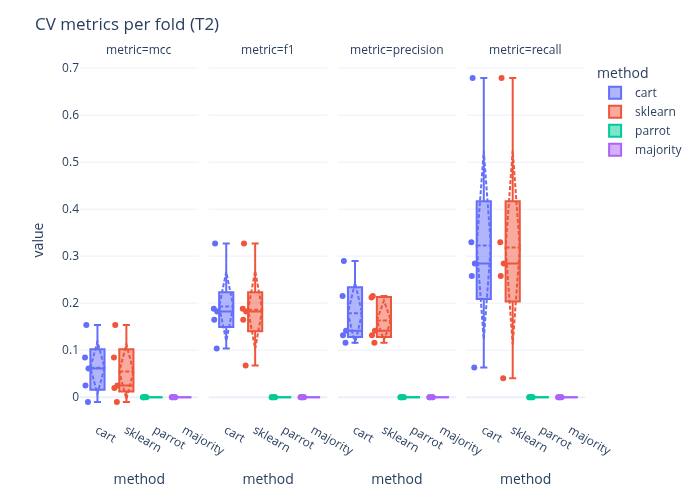

[11/03/26 14:40:13] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_cv_folds_T2.*

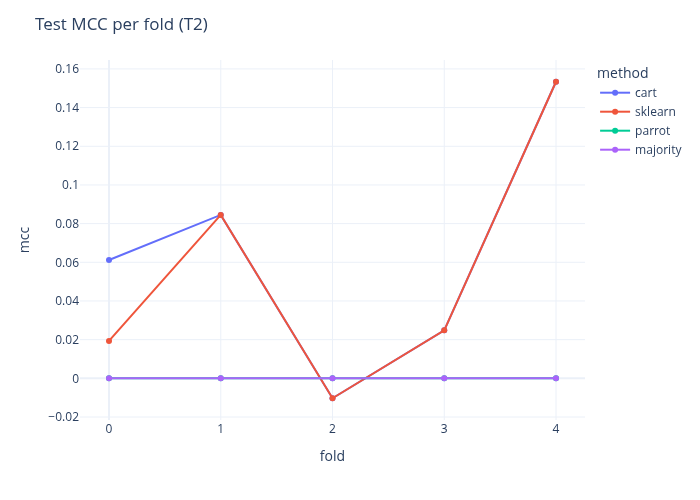

,mcc,f1,precision,recall,accuracy,pct_builds_saved,pct_failures_caught
T1 (mean ± std),,,,,,,
cart,0.232 ± 0.177,0.327 ± 0.284,0.497 ± 0.173,0.295 ± 0.272,0.802 ± 0.076,84.810 ± 17.711,29.456 ± 27.187
majority,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.768 ± 0.136,100.000 ± 0.000,0.000 ± 0.000
parrot,0.269 ± 0.154,0.427 ± 0.192,0.435 ± 0.195,0.421 ± 0.190,0.771 ± 0.063,77.412 ± 13.297,42.073 ± 19.042
sklearn,0.236 ± 0.181,0.329 ± 0.288,0.499 ± 0.176,0.297 ± 0.276,0.805 ± 0.071,84.766 ± 17.799,29.745 ± 27.629


[11/03/26 14:40:17] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_cv_box_T1.*

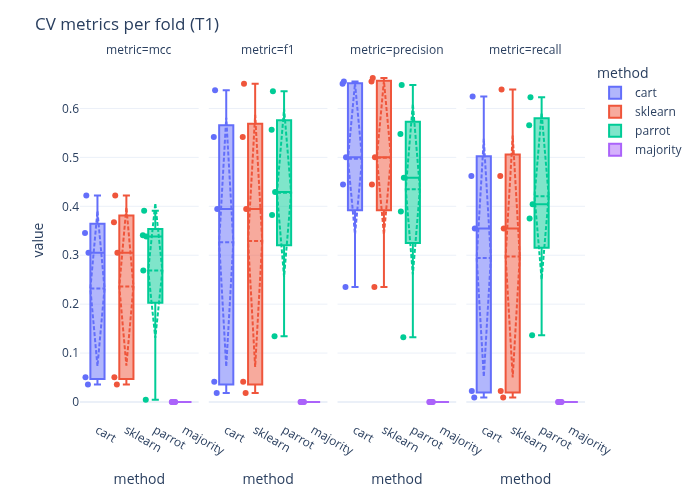

[11/03/26 14:40:21] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_cv_folds_T1.*

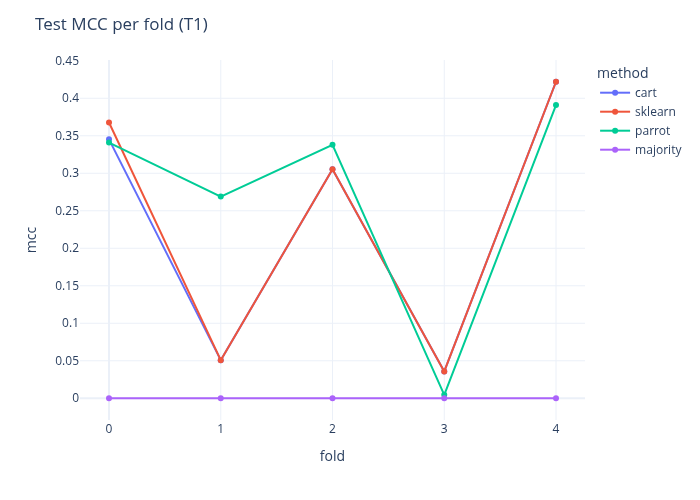

In [10]:
def mean_std(r: pd.DataFrame, metrics: list[str]) -> pd.DataFrame:
    """'mean ± std' per method over the folds (sample std, ddof=1)."""
    g = r.groupby("method")[metrics]
    return g.mean().map(lambda v: f"{v:.3f}") + " ± " + g.std().map(lambda v: f"{v:.3f}")


for t in TARGETS:
    display(mean_std(results[t], METRICS).rename_axis(f"{t} (mean ± std)"))
    long = results[t].melt(id_vars=["method", "fold"], value_vars=["mcc", "f1", "precision", "recall"], var_name="metric")
    display(plots.save(plots.metrics_box(long).update_layout(title=f"CV metrics per fold ({t})"), f"tree_cv_box_{t}"))
    display(plots.save(
        px.line(results[t], x="fold", y="mcc", color="method", markers=True).update_layout(title=f"Test MCC per fold ({t})"),
        f"tree_cv_folds_{t}",
    ))

## 5. Statistical tests

Paired two-sided Wilcoxon signed-rank test on the per-fold MCC, and the Vargha-Delaney A12 (P(CART fold > other fold); 0.5 = no difference). **With 5 folds the smallest reachable two-sided p is 0.0625** (`min_p`), so no comparison can reach 0.05: A12 and the per-fold table carry the result.

In [11]:
rows = []
for t in TARGETS:
    pf = st.per_fold(results[t], "mcc")
    for other in ("parrot", "majority", "sklearn"):
        w = st.paired_wilcoxon(pf["cart"], pf[other])
        rows.append(
            {
                "target": t,
                "cart vs": other,
                "mean_diff": (pf["cart"] - pf[other]).mean(),
                "p": w.p,
                "n": w.n,
                "min_p": w.min_p,
                "flag": w.flag,
                "A12": st.vargha_delaney_a12(pf["cart"], pf[other]),
            }
        )
display(pd.DataFrame(rows).round(4))
{t: st.per_fold(results[t], "mcc").round(3) for t in TARGETS}

,target,cart vs,mean_diff,p,n,min_p,flag,A12
0,T2,parrot,0.0627,0.1250,5,0.0625,NaN,0.80
1,T2,majority,0.0627,0.1250,5,0.0625,NaN,0.80
2,T2,sklearn,0.0084,1.0000,1,1.0000,zero_diffs_dropped,0.56
3,T1,parrot,-0.0369,0.8125,5,0.0625,NaN,0.52
4,T1,majority,0.2318,0.0625,5,0.0625,NaN,1.00
5,T1,sklearn,-0.0045,1.0000,1,1.0000,zero_diffs_dropped,0.48


{'T2': method   cart  majority  parrot  sklearn
 fold                                    
 0       0.061       0.0     0.0    0.019
 1       0.084       0.0     0.0    0.084
 2      -0.010       0.0     0.0   -0.010
 3       0.025       0.0     0.0    0.025
 4       0.153       0.0     0.0    0.153,
 'T1': method   cart  majority  parrot  sklearn
 fold                                    
 0       0.345       0.0   0.341    0.368
 1       0.051       0.0   0.269    0.051
 2       0.305       0.0   0.338    0.305
 3       0.036       0.0   0.005    0.036
 4       0.422       0.0   0.391    0.422}

## 6. What the tree uses

Impurity-decrease importance of each fold's final (pruned) tree. The table gives the mean and std over the folds; the plot shows one point per fold and the dashed line is the mean. No ± std band here: importances are bounded at 0 and skewed (a feature can be large in one fold and 0 in the others), so mean − std would fall below 0.

,0,1,2,3,4,mean,std
T2,,,,,,,
fail_rate_7d,0.000,0.690,0.630,0.739,0.709,0.554,0.312
fail_rate_last_20,0.406,0.040,0.034,0.088,0.096,0.133,0.155
runs_since_last_fail,0.352,0.044,0.060,0.000,0.000,0.091,0.148
file_prior_changes,0.150,0.076,0.075,0.018,0.032,0.070,0.052
files_since_green,0.046,0.027,0.075,0.043,0.055,0.049,0.018
src_files,0.047,0.049,0.039,0.032,0.042,0.042,0.007
n_dirs_touched,0.000,0.039,0.016,0.023,0.023,0.020,0.014
secs_since_last_fail,0.000,0.016,0.044,0.010,0.014,0.017,0.017
config_files,0.000,0.012,0.013,0.028,0.019,0.015,0.010


[11/03/26 14:40:25] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_importance_T2.*

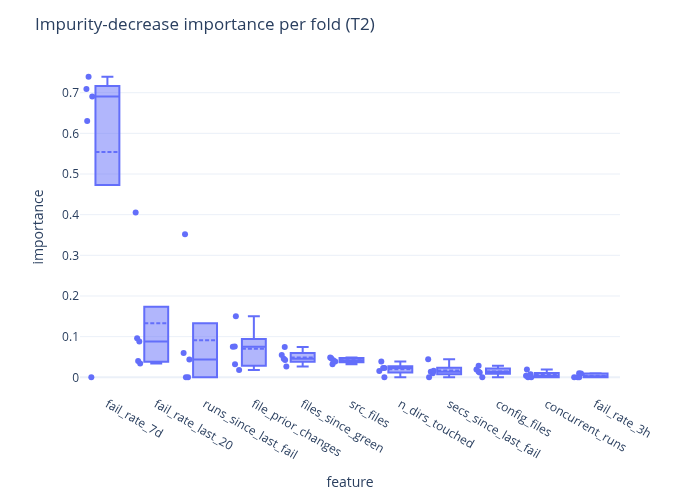

,0,1,2,3,4,mean,std
T1,,,,,,,
fail_rate_last_10,0.000,0.003,0.015,0.743,0.671,0.286,0.385
fail_rate_7d,0.600,0.699,0.007,0.039,0.032,0.275,0.344
fail_rate_last_50,0.010,0.013,0.806,0.047,0.068,0.189,0.346
files_since_prev_run,0.054,0.040,0.033,0.037,0.040,0.041,0.008
file_distinct_authors,0.062,0.037,0.026,0.035,0.039,0.040,0.014
file_age_mean,0.053,0.056,0.000,0.008,0.021,0.028,0.026
days_since_workflow_change,0.032,0.042,0.010,0.015,0.026,0.025,0.013
prev_failed_jobs,0.039,0.018,0.006,0.025,0.012,0.020,0.013
secs_since_last_fail,0.052,0.015,0.006,0.000,0.008,0.016,0.021


[11/03/26 14:40:28] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_importance_T1.*

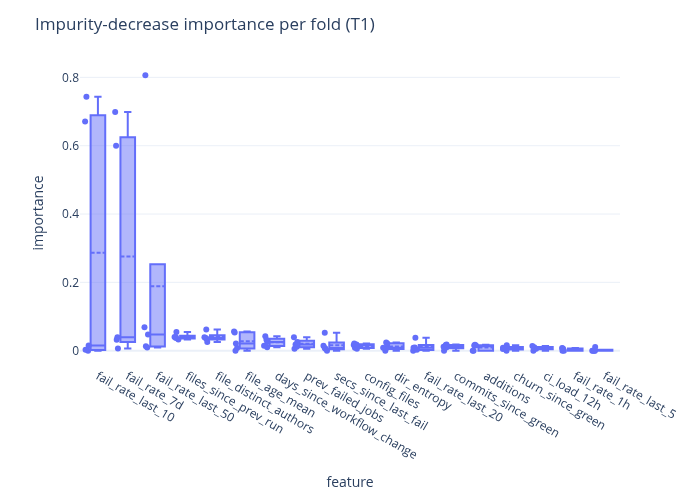

In [12]:
for t in TARGETS:
    imp = pd.DataFrame({k: p["tree"].feature_importances_ for k, p in payloads[t].items()}, index=feats[t])
    imp = imp.loc[imp.mean(axis=1).sort_values(ascending=False).index]
    display(imp.assign(mean=imp.mean(axis=1), std=imp.std(axis=1)).round(3).rename_axis(t))
    long = imp.rename_axis("feature").reset_index().melt(id_vars="feature", var_name="fold", value_name="importance")
    display(plots.save(
        px.box(long, x="feature", y="importance", points="all", hover_data=["fold"])
        .update_traces(boxmean=True)
        .update_layout(title=f"Impurity-decrease importance per fold ({t})"),
        f"tree_importance_{t}",
    ))

The tree of the last fold (largest train set), top 3 levels. Box width = runs reaching the node, colour = P(fail).

|--- fail_rate_7d <= 0.421311
|   |--- fail_rate_last_20 <= 0.183333
|   |   |--- n_dirs_touched <= 14.5
|   |   |   |--- ...
|   |   |--- n_dirs_touched > 14.5
|   |   |   |--- ...
|   |--- fail_rate_last_20 > 0.183333
|   |   |--- fail_rate_7d <= 0.122155
|   |   |   |--- ...
|   |   |--- fail_rate_7d > 0.122155
|   |   |   |--- ...
|--- fail_rate_7d > 0.421311
|   |--- files_since_green <= 8.5
|   |   |--- fail_rate_last_20 <= 0.375
|   |   |   |--- leaf: P(fail) = 0.19 from 42 runs
|   |   |--- fail_rate_last_20 > 0.375
|   |   |   |--- ...
|   |--- files_since_green > 8.5
|   |   |--- fail_rate_last_20 <= 0.475
|   |   |   |--- ...
|   |   |--- fail_rate_last_20 > 0.475
|   |   |   |--- ...


[11/03/26 14:40:32] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_icicle_T2.*

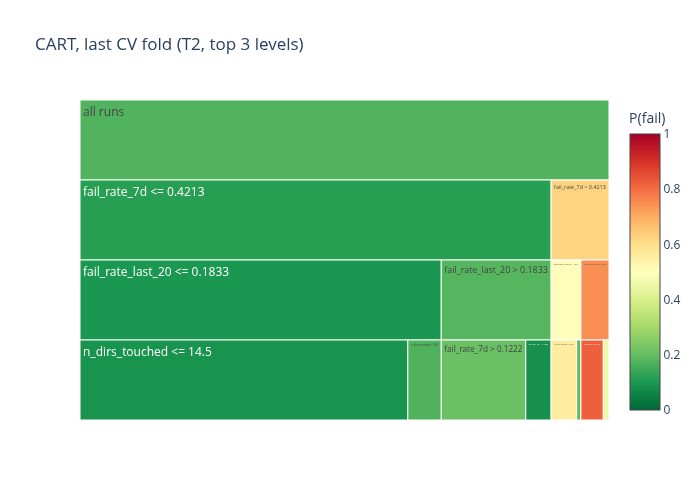

In [13]:
last = payloads["T2"][max(payloads["T2"])]["tree"]
print(last.export_text(max_depth=3))
plots.save(
    plots.tree_icicle(last.tree_, last.feature_names_, max_depth=3).update_layout(title="CART, last CV fold (T2, top 3 levels)"),
    "tree_icicle_T2",
)

## 7. Errors and the cost trade-off

Confusion matrix of CART, pooled over the 5 test folds.

[11/03/26 14:40:36] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_confusion_T2.*

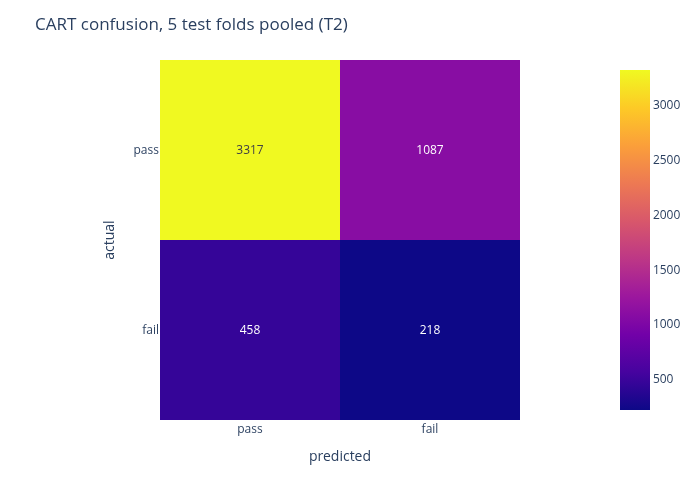

[11/03/26 14:40:41] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_confusion_T1.*

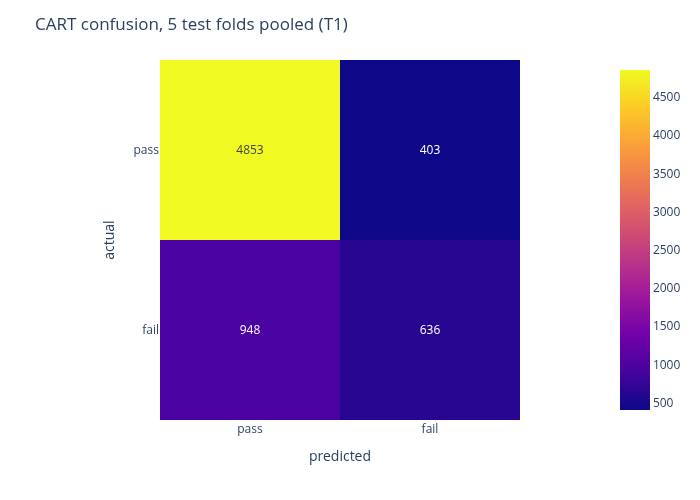

In [14]:
def pooled(t: str, method: str) -> pd.Series:
    return results[t].query("method == @method")[["tn", "fp", "fn", "tp"]].sum()


for t in TARGETS:
    c = pooled(t, "cart")
    display(plots.save(
        plots.confusion(np.array([[c.tn, c.fp], [c.fn, c.tp]])).update_layout(title=f"CART confusion, 5 test folds pooled ({t})"),
        f"tree_confusion_{t}",
    ))

**Trade-off.** Each fold's tree scores its test fold; the probabilities are pooled and one threshold is swept over all of them. A higher threshold skips more builds (`% builds saved`) and catches fewer failures. The star is CART with its tuned per-fold thresholds; the diamond is Parrot. The dotted line is a random guess that flags a share q of the builds and so catches a share q of the failures (caught = 100 − saved): the distance above it is what the model adds.

**Pooled, not averaged.** Every point here counts all test runs together, so folds with more failures weigh more. It differs from the fold means above (e.g. T1 recall: pooled 40%, mean over folds 29.5%). A single global threshold read off this curve uses the test labels, so it is a diagnosis of the threshold choice, not a result.

[11/03/26 14:40:46] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_tradeoff_T2.*

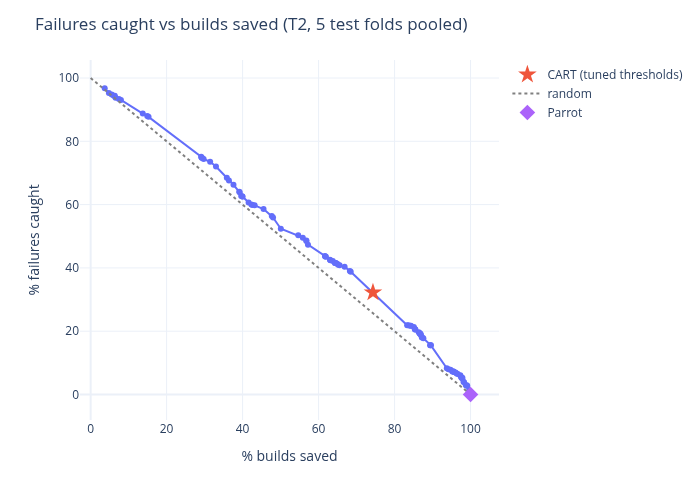

[11/03/26 14:40:51] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/tree_tradeoff_T1.*

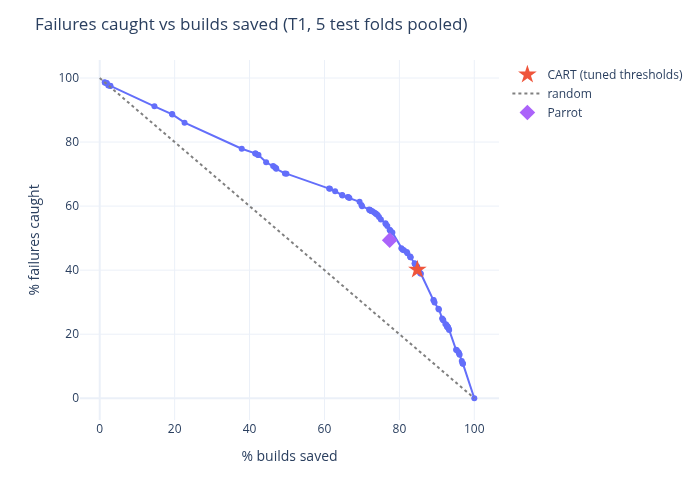

In [15]:
def point(c: pd.Series) -> tuple[float, float]:
    return 100 * (c.tn + c.fn) / c.sum(), 100 * c.tp / (c.tp + c.fn)


for t in TARGETS:
    proba = np.concatenate([payloads[t][k]["tree"].predict_proba(s.X_test)[:, 1] for k, s in enumerate(splits[t])])
    y = np.concatenate([data[t].y.iloc[f.test].to_numpy() for f in fold_lists[t]]).astype(bool)
    curve = pd.DataFrame(
        [
            {"threshold": th, "saved": 100 * np.mean(proba <= th), "caught": 100 * np.mean(proba[y] > th)}
            for th in np.unique(np.r_[0.0, proba])
        ]
    )
    fig = plots.tradeoff(curve, point(pooled(t, "cart")), "CART (tuned thresholds)")
    fig.add_scatter(x=[0, 100], y=[100, 0], mode="lines", name="random", line={"dash": "dot", "color": "grey"})
    px_ = point(pooled(t, "parrot"))
    fig.add_scatter(x=[px_[0]], y=[px_[1]], mode="markers", name="Parrot", marker={"symbol": "diamond", "size": 12})
    display(plots.save(fig.update_layout(title=f"Failures caught vs builds saved ({t}, 5 test folds pooled)"), f"tree_tradeoff_{t}"))

## 8. Sensitivity: without the failure regime

The same CV, grid and features, with the runs created between 2026-02-10 and 2026-06-10 removed. The dev rows lie before the regime, so the dev segment and the frozen lists do not change; the folds are rebuilt over the remaining rows.

In [16]:
def without_regime(ds: Dataset) -> Dataset:
    start, end = (pd.Timestamp(d, tz="UTC") for d in REGIME)
    keep = ~ds.order.between(start, end).to_numpy()
    y = ds.y[keep].reset_index(drop=True)
    return replace(
        ds,
        X=ds.X[keep].reset_index(drop=True),
        y=y,
        dev_mask=ds.dev_mask[keep],
        order=ds.order[keep].reset_index(drop=True),
        meta=ds.meta | {"n_rows": len(y), "n_failed": int(y.sum())},
    )


sens = {}
for t in TARGETS:
    ds = without_regime(data[t])
    assert ds.dev_mask.sum() == data[t].dev_mask.sum(), "dev rows must lie before the regime"
    print(f"{t}: {data[t].meta['n_rows']} -> {ds.meta['n_rows']} rows, fail {100 * ds.y.mean():.1f}%")
    sens[t] = pd.concat(
        [run_cv(ds, feats[t], tune.fit_predict, "cart")[0], run_cv(ds, feats[t], parrot, "parrot")[0]],
        ignore_index=True,
    )

pd.concat(
    {
        (t, name): mean_std(r[r.method.isin(["cart", "parrot"])], ["mcc", "f1", "precision", "recall"])
        for t in TARGETS
        for name, r in (("all runs", results[t]), ("no regime", sens[t]))
    }
)

Output()

[11/03/26 14:40:53] INFO     cart fold 1/5: fit 1889, val 472, test 833 (91 failures)

T2: 7626 -> 6526 rows, fail 11.8%


[11/03/26 14:40:57] INFO     cart fold 2/5: fit 2556, val 638, test 833 (93 failures)

[11/03/26 14:41:03] INFO     cart fold 3/5: fit 3222, val 805, test 833 (89 failures)

[11/03/26 14:41:11] INFO     cart fold 4/5: fit 3888, val 972, test 833 (111 failures)

... (17 outputs left out)

                    INFO     parrot fold 3/5: fit 3916, val 978, test 946 (128 failures)

                    INFO     parrot fold 4/5: fit 4672, val 1168, test 946 (147 failures)

                    INFO     parrot fold 5/5: fit 5429, val 1357, test 946 (279 failures)

mcc             f1      precision  \
             method                                                
T2 all runs  cart    0.063 ± 0.062  0.193 ± 0.082  0.179 ± 0.073   
             parrot  0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000   
   no regime cart    0.040 ± 0.038  0.141 ± 0.130  0.099 ± 0.096   
             parrot  0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000   
T1 all runs  cart    0.232 ± 0.177  0.327 ± 0.284  0.497 ± 0.173   
             parrot  0.269 ± 0.154  0.427 ± 0.192  0.435 ± 0.195   
   no regime cart    0.257 ± 0.164  0.290 ± 0.212  0.552 ± 0.156   
             parrot  0.275 ± 0.174  0.398 ± 0.170  0.403 ± 0.174   

                            recall  
             method                 
T2 all runs  cart    0.323 ± 0.224  
             parrot  0.000 ± 0.000  
   no regime cart    0.297 ± 0.306  
             parrot  0.000 ± 0.000  
T1 all runs  cart    0.295 ± 0.272  
             parrot  0.421 ± 0.190  
   no regime cart    0.229 ± 0.181  
             parrot  0.394 ± 0.167

## 9. Random forest (bagging over CART)

CART alone is weak: on T2 its mean MCC is 0.063, and on T1 it stays below Parrot. A random forest (Breiman, 2001; `tree/forest.py`) averages 100 of our own CART trees. Each tree is fitted on a bootstrap sample of the fit rows and draws √p columns at every node, so the trees differ and part of their errors cancel. P(fail) is the mean of the trees' leaf shares.

**Protocol.** Same folds, features and validation tail as CART. The trees are not pruned. The grid (`max_depth` ∈ {8, None} × `min_samples_leaf` ∈ {5, 20} × class weight = 8 points) and the decision threshold are chosen on validation MCC; each test fold is read once. The seed is fixed (`random_state=0`), so each fold is run once, as for CART.

**What it costs.** A forest has no single readable path, so it is not the model we explain. It shows how much accuracy the single tree gives up for its explanation.

In [17]:
rf_payloads = {}
for t in TARGETS:
    print(f"Target: {t}")
    rf, rf_payloads[t] = run_cv(data[t], feats[t], forest.fit_predict, "forest")
    # drop an earlier forest run first, so the cell can be re-run
    results[t] = pd.concat([results[t].query("method != 'forest'"), rf], ignore_index=True)

Output()

[11/03/26 14:41:59] INFO     forest fold 1/5: fit 2037, val 509, test 1016 (175 failures)

Target: T2


[11/03/26 14:42:22] INFO     forest fold 2/5: fit 2850, val 712, test 1016 (88 failures)

[11/03/26 14:42:48] INFO     forest fold 3/5: fit 3663, val 915, test 1016 (123 failures)

[11/03/26 14:43:20] INFO     forest fold 4/5: fit 4476, val 1118, test 1016 (128 failures)

... (4 outputs left out)

[11/03/26 14:45:13] INFO     forest fold 2/5: fit 3835, val 958, test 1368 (216 failures)

[11/03/26 14:45:50] INFO     forest fold 3/5: fit 4929, val 1232, test 1368 (203 failures)

[11/03/26 14:46:43] INFO     forest fold 4/5: fit 6024, val 1505, test 1368 (176 failures)

[11/03/26 14:47:40] INFO     forest fold 5/5: fit 7118, val 1779, test 1368 (366 failures)

Choice per fold, with the validation MCC it was chosen on, the test MCC, and CART's test MCC on the same fold.

In [18]:
rf_mcc = {t: results[t].query("method == 'forest'").set_index("fold")["mcc"] for t in TARGETS}
pd.DataFrame(
    [
        {
            "target": t,
            "fold": k,
            **p["choice"].params,
            "threshold": p["choice"].threshold,
            "mean_depth": np.mean([tr.depth_ for tr in p["forest"].estimators_]),
            "val_mcc": p["choice"].val_mcc,
            "test_mcc": rf_mcc[t][k],
            "cart_test_mcc": test_mcc[t][k],
        }
        for t in TARGETS
        for k, p in rf_payloads[t].items()
    ]
).round(4)

,target,fold,max_depth,min_samples_leaf,class_weight,threshold,mean_depth,val_mcc,test_mcc,cart_test_mcc
0,T2,0,NaN,5,balanced,0.5994,19.09,0.3606,0.1087,0.0612
1,T2,1,NaN,5,balanced,0.4776,18.97,0.1902,0.0655,0.0845
2,T2,2,8.0,20,NaN,0.1558,8.00,0.1180,0.0217,-0.0103
3,T2,3,NaN,20,balanced,0.5551,15.76,0.0975,-0.0359,0.0248
4,T2,4,8.0,20,NaN,0.0917,8.00,0.0853,0.0946,0.1534
5,T1,0,8.0,20,balanced,0.8497,8.00,0.3225,0.4434,0.3452
6,T1,1,NaN,20,balanced,0.7549,15.12,0.5377,0.0000,0.0508
7,T1,2,8.0,20,NaN,0.3692,8.00,0.3046,0.3277,0.3052
8,T1,3,8.0,5,balanced,0.4910,8.00,0.3954,0.0083,0.0357
9,T1,4,NaN,20,NaN,0.6482,19.43,0.0905,0.4340,0.4220


Mean ± std over the 5 test folds, next to CART and the baselines (same plots as section 4).

,mcc,f1,precision,recall,accuracy,pct_builds_saved,pct_failures_caught
T2 (mean ± std),,,,,,,
cart,0.063 ± 0.062,0.193 ± 0.082,0.179 ± 0.073,0.323 ± 0.224,0.696 ± 0.099,74.311 ± 16.784,32.276 ± 22.371
forest,0.051 ± 0.059,0.151 ± 0.108,0.170 ± 0.135,0.306 ± 0.378,0.688 ± 0.249,73.248 ± 35.398,30.624 ± 37.751
majority,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.867 ± 0.034,100.000 ± 0.000,0.000 ± 0.000
parrot,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.867 ± 0.034,100.000 ± 0.000,0.000 ± 0.000


[11/03/26 14:49:02] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/forest_cv_box_T2.*

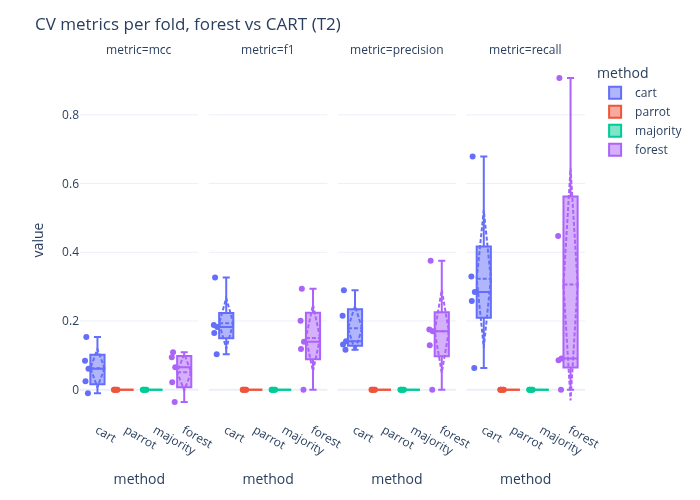

[11/03/26 14:49:06] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/forest_cv_folds_T2.*

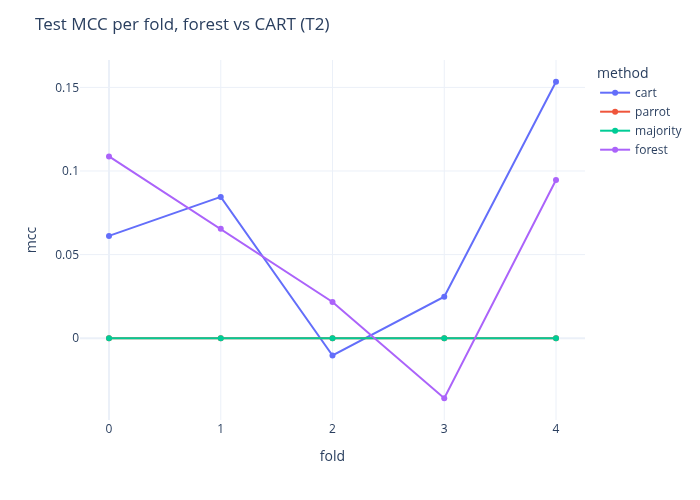

,mcc,f1,precision,recall,accuracy,pct_builds_saved,pct_failures_caught
T1 (mean ± std),,,,,,,
cart,0.232 ± 0.177,0.327 ± 0.284,0.497 ± 0.173,0.295 ± 0.272,0.802 ± 0.076,84.810 ± 17.711,29.456 ± 27.187
forest,0.243 ± 0.222,0.299 ± 0.266,0.465 ± 0.376,0.223 ± 0.201,0.814 ± 0.063,90.819 ± 9.419,22.321 ± 20.149
majority,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.768 ± 0.136,100.000 ± 0.000,0.000 ± 0.000
parrot,0.269 ± 0.154,0.427 ± 0.192,0.435 ± 0.195,0.421 ± 0.190,0.771 ± 0.063,77.412 ± 13.297,42.073 ± 19.042


[11/03/26 14:49:11] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/forest_cv_box_T1.*

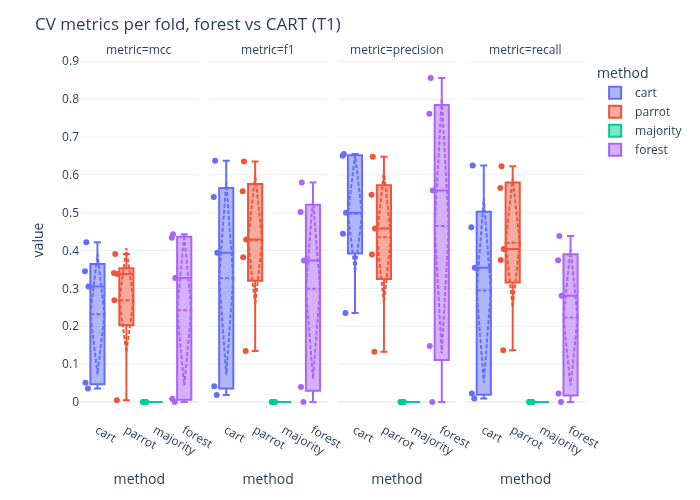

[11/03/26 14:49:15] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/forest_cv_folds_T1.*

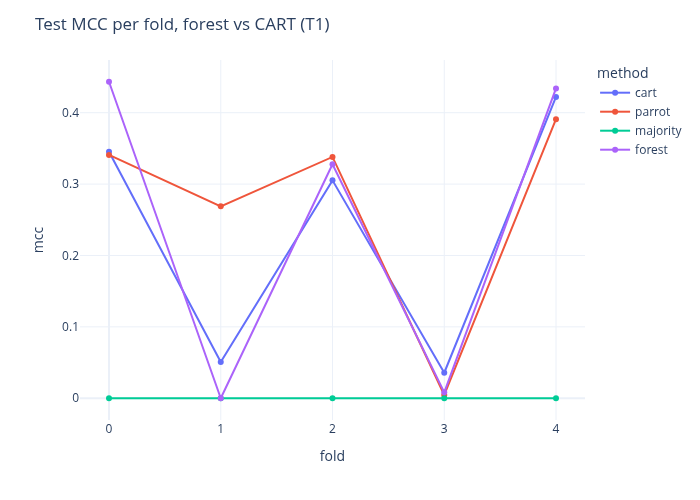

In [19]:
COMPARE = ["forest", "cart", "parrot", "majority"]
for t in TARGETS:
    r = results[t][results[t].method.isin(COMPARE)]
    display(mean_std(r, METRICS).rename_axis(f"{t} (mean ± std)"))
    long = r.melt(id_vars=["method", "fold"], value_vars=["mcc", "f1", "precision", "recall"], var_name="metric")
    display(plots.save(plots.metrics_box(long).update_layout(title=f"CV metrics per fold, forest vs CART ({t})"), f"forest_cv_box_{t}"))
    display(plots.save(
        px.line(r, x="fold", y="mcc", color="method", markers=True).update_layout(title=f"Test MCC per fold, forest vs CART ({t})"),
        f"forest_cv_folds_{t}",
    ))

**Statistical tests.** As in section 5: paired Wilcoxon on the per-fold MCC (smallest reachable p with 5 folds: 0.0625) and A12 = P(forest fold > other fold).

In [20]:
rows = []
for t in TARGETS:
    pf = st.per_fold(results[t], "mcc")
    for other in ("cart", "parrot", "majority"):
        w = st.paired_wilcoxon(pf["forest"], pf[other])
        rows.append(
            {
                "target": t,
                "forest vs": other,
                "mean_diff": (pf["forest"] - pf[other]).mean(),
                "p": w.p,
                "n": w.n,
                "min_p": w.min_p,
                "flag": w.flag,
                "A12": st.vargha_delaney_a12(pf["forest"], pf[other]),
            }
        )
pd.DataFrame(rows).round(4)

,target,forest vs,mean_diff,p,n,min_p,flag,A12
0,T2,cart,-0.0118,0.6250,5,0.0625,NaN,0.48
1,T2,parrot,0.0509,0.1875,5,0.0625,NaN,0.80
2,T2,majority,0.0509,0.1875,5,0.0625,NaN,0.80
3,T1,cart,0.0109,1.0000,5,0.0625,NaN,0.52
4,T1,parrot,-0.0260,1.0000,5,0.0625,NaN,0.52
5,T1,majority,0.2427,0.1250,4,0.1250,zero_diffs_dropped,0.90


**What the forest uses.** Impurity-decrease importance averaged over the 100 trees, then over the 5 folds, next to CART's mean from section 6. The column draw forces the forest to split on features the single tree never reaches, so its importances are spread more evenly.

,forest,cart
T2,,
fail_rate_7d,0.274,0.554
fail_rate_last_20,0.199,0.133
fail_rate_3h,0.090,0.004
secs_since_last_fail,0.088,0.017
file_prior_changes,0.084,0.070
runs_since_last_fail,0.079,0.091
files_since_green,0.063,0.049
n_dirs_touched,0.047,0.020
src_files,0.045,0.042


[11/03/26 14:49:19] INFO     Saved figure:                                                                         
                             /home/aprofir/uni/ACISE/projects/2/results/figures/forest_importance_T2.*

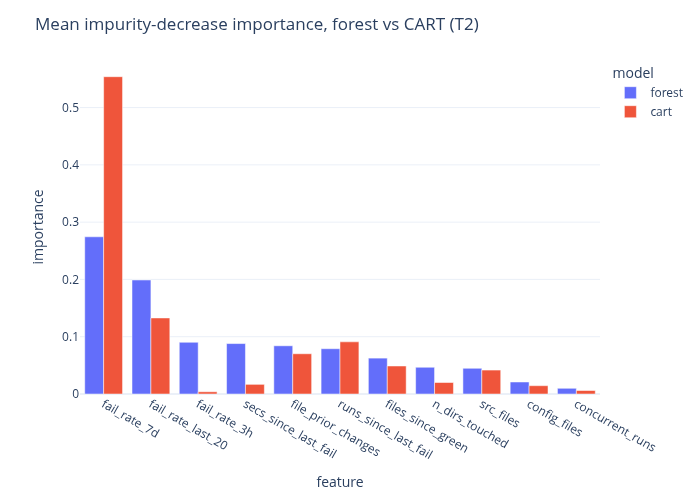

,forest,cart
T1,,
fail_rate_last_50,0.182,0.189
fail_rate_last_10,0.151,0.286
fail_rate_7d,0.144,0.275
fail_rate_last_20,0.141,0.012
fail_rate_last_5,0.067,0.002
prev_failed_jobs,0.038,0.020
secs_since_last_fail,0.034,0.016
file_distinct_authors,0.030,0.040
fail_rate_1h,0.029,0.004


[11/03/26 14:49:23] INFO     Saved figure:                                                                         
                             /home/aprofir/uni/ACISE/projects/2/results/figures/forest_importance_T1.*

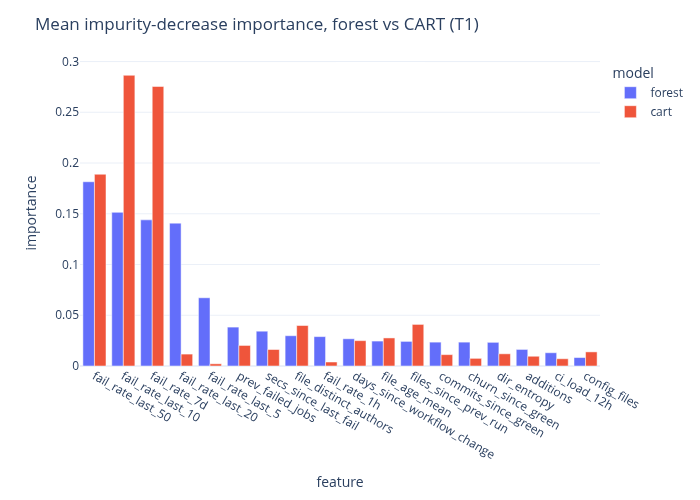

In [21]:
for t in TARGETS:
    imp = pd.DataFrame(
        {
            "forest": np.mean([p["forest"].feature_importances_ for p in rf_payloads[t].values()], axis=0),
            "cart": np.mean([p["tree"].feature_importances_ for p in payloads[t].values()], axis=0),
        },
        index=feats[t],
    ).sort_values("forest", ascending=False)
    display(imp.round(3).rename_axis(t))
    long = imp.rename_axis("feature").reset_index().melt(id_vars="feature", var_name="model", value_name="importance")
    display(plots.save(
        px.bar(long, x="feature", y="importance", color="model", barmode="group")
        .update_layout(title=f"Mean impurity-decrease importance, forest vs CART ({t})"),
        f"forest_importance_{t}",
    ))

**Trade-off.** The pooled curve of section 7, for the forest and CART on the same axes. The forest gives almost every run its own P(fail), so its curve is drawn at 201 quantile thresholds. The star is the forest with its tuned per-fold thresholds. As in section 7, the curve uses the test labels and is a diagnosis of the ranking, not a result.

[11/03/26 14:49:28] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/forest_tradeoff_T2.*

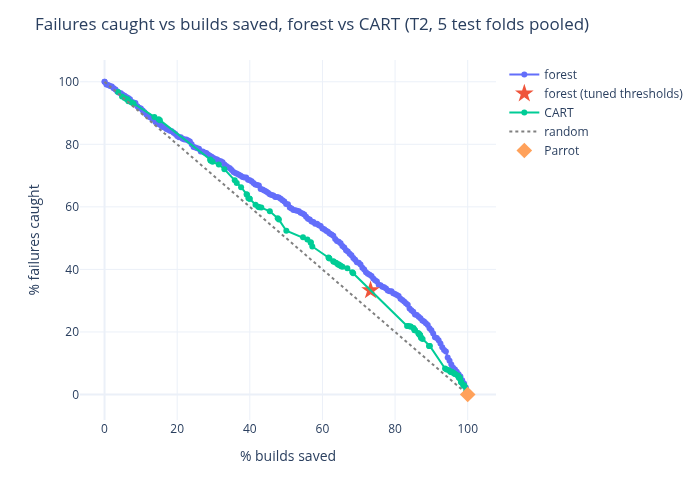

[11/03/26 14:49:32] INFO     Saved figure: /home/aprofir/uni/ACISE/projects/2/results/figures/forest_tradeoff_T1.*

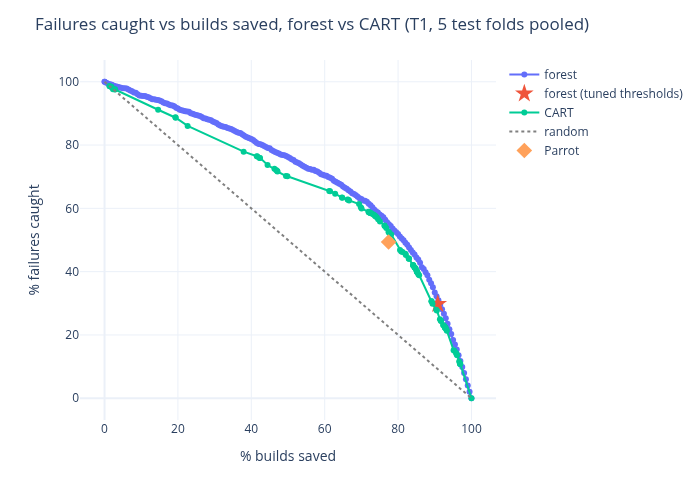

In [22]:
def sweep(proba: np.ndarray, y: np.ndarray, thresholds: np.ndarray) -> pd.DataFrame:
    return pd.DataFrame(
        [{"threshold": th, "saved": 100 * np.mean(proba <= th), "caught": 100 * np.mean(proba[y] > th)} for th in thresholds]
    )


for t in TARGETS:
    y = np.concatenate([data[t].y.iloc[f.test].to_numpy() for f in fold_lists[t]]).astype(bool)
    p_rf = np.concatenate([rf_payloads[t][k]["forest"].predict_proba(s.X_test)[:, 1] for k, s in enumerate(splits[t])])
    p_cart = np.concatenate([payloads[t][k]["tree"].predict_proba(s.X_test)[:, 1] for k, s in enumerate(splits[t])])
    fig = plots.tradeoff(
        sweep(p_rf, y, np.unique(np.r_[0.0, np.quantile(p_rf, np.linspace(0, 1, 201))])),
        point(pooled(t, "forest")),
        "forest (tuned thresholds)",
    )
    fig.data[0].update(name="forest", showlegend=True)
    c = sweep(p_cart, y, np.unique(np.r_[0.0, p_cart]))
    fig.add_scatter(x=c.saved, y=c.caught, mode="lines+markers", name="CART")
    fig.add_scatter(x=[0, 100], y=[100, 0], mode="lines", name="random", line={"dash": "dot", "color": "grey"})
    px_ = point(pooled(t, "parrot"))
    fig.add_scatter(x=[px_[0]], y=[px_[1]], mode="markers", name="Parrot", marker={"symbol": "diamond", "size": 12})
    display(plots.save(fig.update_layout(title=f"Failures caught vs builds saved, forest vs CART ({t}, 5 test folds pooled)"), f"forest_tradeoff_{t}"))

## Observations

**Walkthrough.** The depth-3 dev tree splits on recent failure history (`runs_since_last_fail`, `secs_since_last_fail`, `fail_rate_7d`) and on change spread (`files_since_green`, `file_prior_changes`). sklearn's tree with the same parameters has the same root impurity and the same 8 leaves, and agrees on 99.2% of the training predictions; the rest are equal-gain ties.

**Overfitting.** Unpruned, the median train MCC rises steadily with depth (0.40 at depth 3, 0.54 at depth 12), while the median validation MCC stays between 0.05 and 0.10 at every depth. Deeper trees only memorise the fit rows, which is why the alpha choice matters: on the dev split it cuts a depth-8 tree back at alpha ≈ 0.0026.

**Dev grid.** The grid is flat: the best validation MCC is 0.20 (Gini, unweighted, `min_samples_leaf=5`), and depths 6 and 8 prune to the same 11-leaf tree.

**CV, T2 (main target).** CART reaches a mean MCC of 0.063 ± 0.062 (folds −0.010 to 0.153), recall 32% and precision 18%, skipping 74% of builds. Parrot and majority predict "pass" everywhere on T2 (MCC 0). CART is above them in every fold but one (A12 = 0.80), but with 5 folds the Wilcoxon p cannot go below 0.0625 (here 0.125). The signal exists but is weak: on runs whose previous run passed, the pre-run features predict little.

**CV, T1.** CART (MCC 0.232 ± 0.177) does not beat Parrot (0.269 ± 0.154); A12 = 0.52, p = 0.81. CART is more precise (0.50 vs 0.44) and catches fewer failures (30% vs 42%). Folds 1 and 3 collapse (MCC 0.05 and 0.04): fold 1 chose a threshold of 0.91 on its validation tail and then almost never predicts "fail".

**Spread between folds.** The std is as large as the mean: on T2 0.062 for a mean MCC of 0.063, and recall swings from 6% to 68% (± 0.22). On T1 the per-fold chart shows folds 0, 2 and 4 near 0.3–0.4 and folds 1 and 3 near 0.05 for CART. Fold 3 is hard for Parrot too (0.005), so it is a hard period; fold 1 is not (Parrot 0.269), so there the tree's own choice fails. With this spread, 5 folds cannot separate CART from Parrot on T1 or confirm the gain over Parrot on T2.

**Trade-off.** On T2 the curve runs only a few points above the random line: at CART's operating point (74% of builds saved) it catches 32% of the failures against 26% for a random guess. On T1 the gap is clear (40% vs 15% at 85% saved), and at Parrot's share of saved builds (77%) the pooled curve catches 52.5% of the failures against Parrot's 49.4%. That threshold is read off the test labels, so it is not a result, but it shows the tree's ranking is about as good as Parrot's; what loses on T1 is the threshold chosen on each validation tail.

**Validation vs test.** The validation MCC that picks each fold's choice does not predict its test MCC (T2 fold 0: 0.351 vs 0.061; T1 fold 3: 0.427 vs 0.036). The chosen configuration also changes from fold to fold (depth 3 to 8, both class weights, thresholds 0.13 to 0.91). The validation tail (500–1,800 rows, the most recent part of train) is too small and too unlike the next test fold for stable choices.

**Implementation.** sklearn with CART's choices gives the same test MCC in 4 of 5 folds on each target (mean differences 0.008 on T2 and −0.005 on T1). The weak results come from the data and the protocol, not from the from-scratch code.

**Importances.** On T2, `fail_rate_7d` carries 63–74% of the importance in folds 1–4; fold 0 (whose train ends inside the regime) uses `fail_rate_last_20` and `runs_since_last_fail` instead. Change features (`file_prior_changes`, `files_since_green`, `src_files`) stay at 2–8%. So even on T2 the tree mostly learns the recent failure level of master, that is, the state of the CI environment, not the pushed change. On T1 the fail-rate windows take turns (`fail_rate_7d` in folds 0–1, `fail_rate_last_50` in fold 2, `fail_rate_last_10` in folds 3–4): they are near-duplicates, so the split goes to whichever is marginally better on that train set.

**Sensitivity.** Without the regime rows, T2 drops to MCC 0.040 ± 0.038 (precision 0.10), and on T1 CART (0.257 ± 0.164) is still below Parrot (0.275 ± 0.174). The regime is not what keeps CART below Parrot on T1, and on T2 it supplies part of the little signal there is.

**Random forest.** 100 bagged CART trees with √p columns per node do not beat the single tree on test MCC: T2 0.051 ± 0.059 vs 0.063 (A12 = 0.48), T1 0.243 ± 0.222 vs 0.232, still below Parrot (0.269; A12 = 0.52, p = 1.0). The pooled trade-off curve tells a different story: the forest's curve lies above CART's on both targets, so it ranks runs better. The gain is lost in the per-fold choices made on the validation tail: validation MCC again does not predict test MCC (T1 fold 1: 0.538 vs 0.000; its 0.75 threshold never predicts "fail"). Importances are spread more evenly (T2 `fail_rate_7d` 27% vs 55% in CART), but the fail-rate windows still lead. A stronger learner does not fix the weak protocol step; a larger or more stable validation scheme would.